# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [3]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

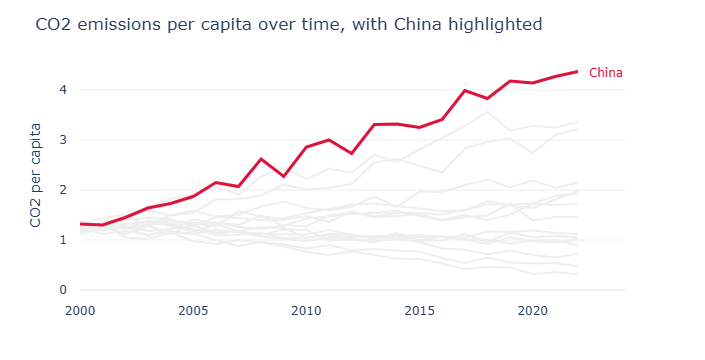

In [64]:
# Task 1: Index by year, with China highlighted

highlight = 'China'

# Draw every country in light grey first
fig = px.line(
    df, x='Year', y='CO2_per_capita', line_group='Country',
    color_discrete_sequence=['#EEEEEE'],
    labels={'Year': '', 'CO2_per_capita': 'CO2 per capita'}
)

# Add China as the coloured line
china = df[df['Country'] == highlight]
fig.add_scatter(
    x=china['Year'], y=china['CO2_per_capita'],
    mode='lines', name=highlight, line=dict(color='crimson', width=3),
    showlegend=False
)

# Label China at the end of its line
last = china[china['Year'] == china['Year'].max()].iloc[0]
fig.add_annotation(
    x=last['Year'], y=last['CO2_per_capita'], text=highlight,
    showarrow=False, xshift=28, font=dict(color='crimson')
)

fig.update_layout(
    title='CO2 emissions per capita over time, with China highlighted',
    template='plotly_white', showlegend=False, margin=dict(l=80, b=70)
)
fig.update_xaxes(showgrid=False, ticklabelstandoff=12, automargin=True)
fig.update_yaxes(showgrid=True, gridcolor='#EEEEEE', rangemode='tozero', ticklabelstandoff=12, automargin=True)
fig.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

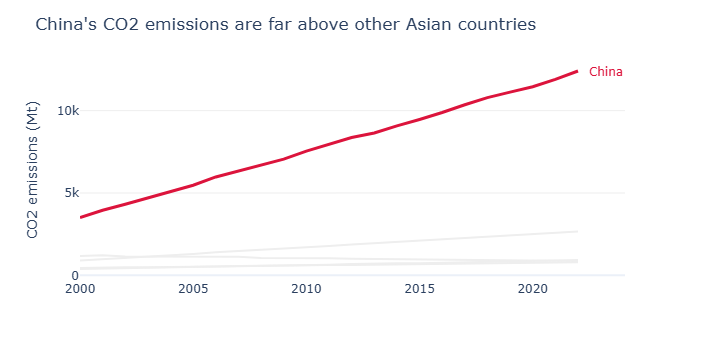

In [43]:
# Task — Multi-series line with highlight
# YOUR CODE HERE
# Task 2: CO2 emissions for Asian countries, with China highlighted

asia = df[df['Region'] == 'Asia']
highlight = 'China'

# Draw every Asian country in light grey first
fig = px.line(
    asia, x='Year', y='CO2_Mt', line_group='Country',
    color_discrete_sequence=['#EEEEEE'],
    labels={'Year': '', 'CO2_Mt': 'CO2 emissions (Mt)'}
)

# Add China as the coloured line
china = asia[asia['Country'] == highlight]
fig.add_scatter(
    x=china['Year'], y=china['CO2_Mt'],
    mode='lines', name=highlight, line=dict(color='crimson', width=3),
    showlegend=False
)

# Label China at the end of its line
last = china[china['Year'] == china['Year'].max()].iloc[0]
fig.add_annotation(
    x=last['Year'], y=last['CO2_Mt'], text=highlight,
    showarrow=False, xshift=28, font=dict(color='crimson')
)

fig.update_layout(
    title="China's CO2 emissions are far above other Asian countries",
    template='plotly_white', showlegend=False
)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=True, gridcolor='#EEEEEE')
fig.show()